## 4.1 Calibración y rectificación estéreo

Intrínsecos y distorsión de cada cámara con `calibrateCamera` sobre el checkerboard; R y T con `stereoCalibrate` (se descartan los pares con error estéreo > 2 px). Luego R y T se refinan con 12 vistas del ChArUco fijando los intrínsecos. Los PKL originales se conservan.

In [1]:
import os
os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"

from pathlib import Path
import cv2
import open3d as o3d
import numpy as np
from src.calibration import calibrate_stereo, refine_stereo, load_pair, rectify_pair
from src.visualization import (
    show_rectification, show_disparity, show_cloud,
    render_geometries, camera_geometries, plot_camera_trajectory, plot_measurement
)
from src.disparity import compute_disparity
from src.reconstruction import compute_local_cloud, transform_cloud_to_world
from src.pose import estimate_camera_pose


In [2]:
DATA = Path("data_propia")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

CHECKERBOARD_PATTERN = (9, 6)  # Esquinas internas del tablero simple
CHECKERBOARD_SQUARE_MM = 28.0
MAX_PAIR_ERROR_PX = 2.0  # Pares con mayor error de reproyeccion estereo se descartan
STEREO_REFERENCE_PAIRS = tuple(range(0, 72, 6))  # 12 vistas; validar con el resto

CHARUCO = {
    "squares": (9, 13),
    "square_mm": 42.0,
    "marker_mm": 31.5,
    "dictionary": cv2.aruco.DICT_5X5_100,
}
charuco_dictionary = cv2.aruco.getPredefinedDictionary(CHARUCO["dictionary"])
charuco_board = cv2.aruco.CharucoBoard(
    CHARUCO["squares"], CHARUCO["square_mm"], CHARUCO["marker_mm"], charuco_dictionary
)

MAX_POSE_RMS = 5.0  # Limite de aceptacion de una pose, en pixeles

In [3]:
checker_calibration, checker_maps = calibrate_stereo(
    DATA / "calib", CHECKERBOARD_PATTERN, CHECKERBOARD_SQUARE_MM,
    max_pair_error=MAX_PAIR_ERROR_PX
)
calibration, maps = refine_stereo(
    DATA / "captures", checker_calibration, charuco_board, STEREO_REFERENCE_PAIRS
)

In [4]:
np.set_printoptions(precision=4, suppress=True)
for key in ["image_size", "left_K", "left_dist", "right_K", "right_dist", "R", "T"]:
    print(f"{key}:\n{calibration[key]}\n")


image_size:
(1920, 1080)

left_K:
[[603.4142   0.     972.654 ]
 [  0.     601.2019 527.0723]
 [  0.       0.       1.    ]]

left_dist:
[[ 0.0101 -0.0291 -0.0007  0.0012  0.0048]]

right_K:
[[605.4191   0.     967.4696]
 [  0.     602.7886 533.8778]
 [  0.       0.       1.    ]]

right_dist:
[[ 0.0123 -0.0302 -0.0007  0.0009  0.0049]]

R:
[[ 1.     -0.0001  0.0099]
 [ 0.0001  1.     -0.0004]
 [-0.0099  0.0004  1.    ]]

T:
[[-59.2112]
 [ -0.2239]
 [  0.2234]]



In [5]:
print(f"RMS checkerboard inicial: {calibration['checkerboard_rms']:.4f} px ({len(calibration['used_pairs'])} pares)")
print(f"RMS ajuste R/T: {calibration['rms']:.4f} px ({len(calibration['reference_pairs'])} pares ChArUco)")

RMS checkerboard inicial: 0.6685 px (28 pares)
RMS ajuste R/T: 1.5187 px (12 pares ChArUco)


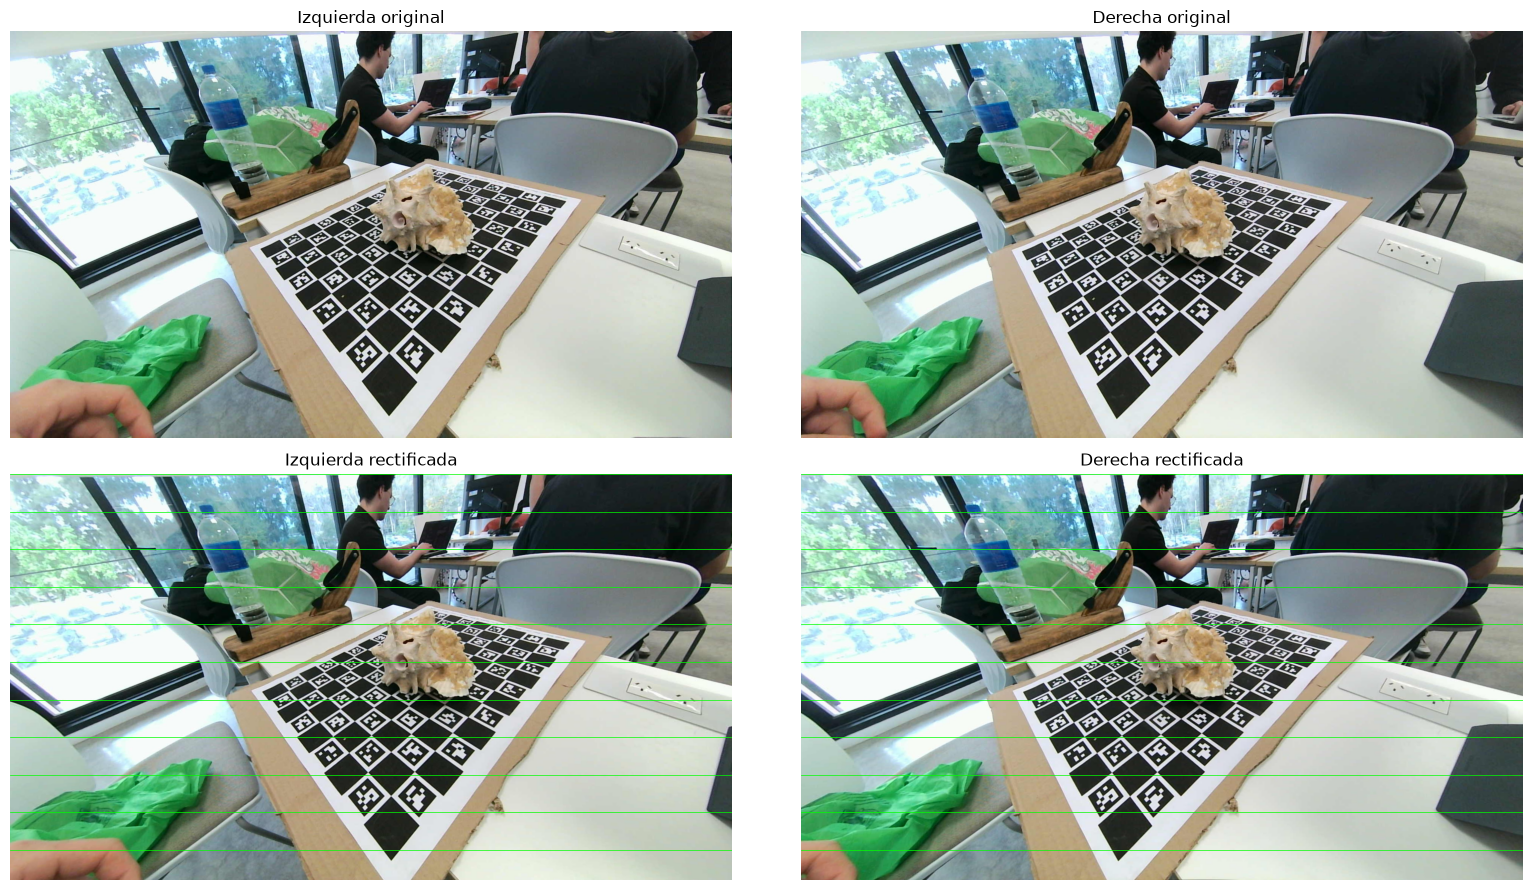

In [6]:
left, right = load_pair(DATA / "captures", 1)
left_rect, right_rect = rectify_pair(left, right, maps)
show_rectification(left, right, left_rect, right_rect, path=FIG / "rectificacion.png")


## 4.2 Disparidad, profundidad y pose de cámaras


In [7]:
disparity = compute_disparity(left_rect, right_rect)

### Nube local


In [8]:
local_cloud = compute_local_cloud(disparity, left_rect, maps["Q"])
local_cloud


PointCloud with 1118950 points.

### Pose global respecto del ChArUco


In [9]:
_, _, camera_pose, pose_rms = estimate_camera_pose(
    left, charuco_board, calibration["left_K"], calibration["left_dist"]
)
print("Pose de la camara izquierda original respecto del tablero:")
print(camera_pose)
print(f"RMS de la pose: {pose_rms:.3f} px")


Pose de la camara izquierda original respecto del tablero:
[[  -0.6653   -0.3686    0.6492  -67.7101]
 [   0.7396   -0.4434    0.5063  -40.5605]
 [   0.1012    0.8171    0.5676 -271.9948]
 [   0.        0.        0.        1.    ]]
RMS de la pose: 0.724 px


### Transformación de la nube al mundo


In [10]:
world_cloud = transform_cloud_to_world(local_cloud, camera_pose, maps["R1"])


### Visualizaciones sugeridas


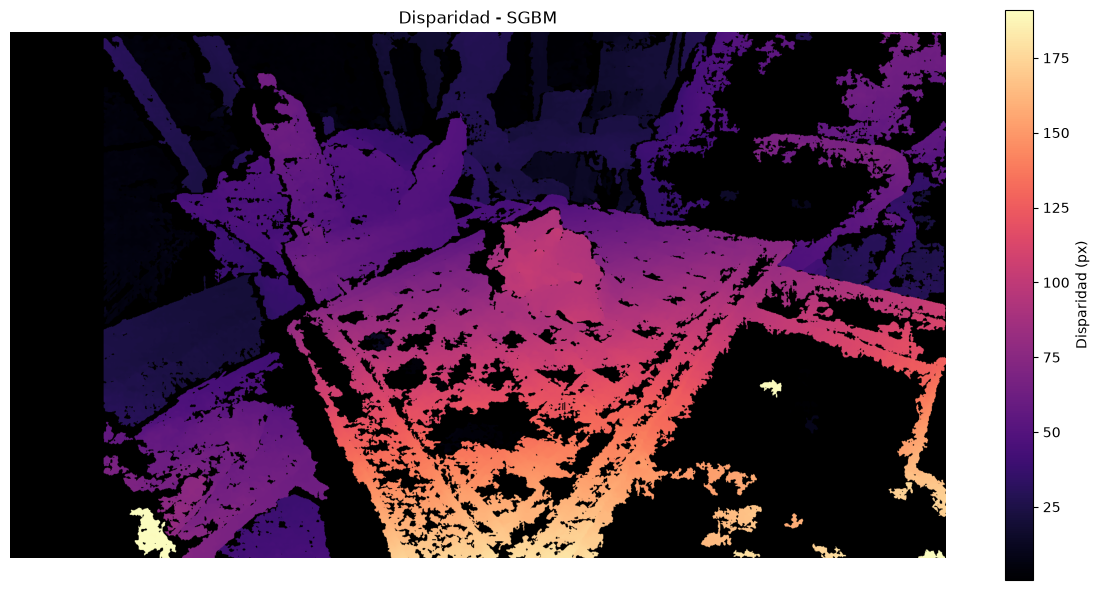

In [11]:
show_disparity(disparity, path=FIG / "disparidad.png")

In [ ]:
show_cloud(local_cloud)

In [ ]:
show_cloud(
    world_cloud, camera_pose,
    calibration["left_K"], calibration["image_size"]
)


### Validación del refinamiento R/T

El RMS de `stereoCalibrate` no es comparable entre ambas calibraciones (una estima intrínsecos y la otra los fija). Para comparar se usan los pares de captura **no usados** en el refinamiento: se rectifican las esquinas ChArUco detectadas en ambas imágenes y se mide el error vertical |Δy| (alineación epipolar) y la escala de las distancias trianguladas respecto del tablero real.

In [12]:
from src.calibration import validate_stereo

validation_pairs = [n for n in range(83) if n not in STEREO_REFERENCE_PAIRS]
for name, calib, rect_maps in [("Solo checkerboard", checker_calibration, checker_maps),
                               ("Refinado ChArUco", calibration, maps)]:
    rows = validate_stereo(DATA / "captures", calib, rect_maps, charuco_board, validation_pairs)
    print(f"{name:18s} pares={len(rows)}  |dy| medio={rows[:, 2].mean():.3f} px  "
          f"escala media={rows[:, 3].mean():.4f}  desvio={rows[:, 3].std():.4f}")

Solo checkerboard  pares=66  |dy| medio=0.720 px  escala media=0.9804  desvio=0.0157


Refinado ChArUco   pares=66  |dy| medio=0.508 px  escala media=1.0015  desvio=0.0156


In [13]:
# Nube local vista desde la camara (se descarta el fondo lejano solo para la figura).
near = np.flatnonzero(np.asarray(local_cloud.points)[:, 2] < 800)
local_near = local_cloud.select_by_index(near)
render_geometries(
    [local_near, o3d.geometry.TriangleMesh.create_coordinate_frame(size=50)],
    FIG / "nube_local.png", front=[0.3, -0.3, -1], up=[0, -1, 0],
    lookat=np.median(np.asarray(local_near.points), axis=0), zoom=0.25, point_size=1.5
)
# Nube de la captura transformada al marco del tablero, con la camara y los ejes del mundo.
world_near = world_cloud.crop(o3d.geometry.AxisAlignedBoundingBox([-120, -120, -300], [500, 660, 40]))
render_geometries(
    [world_near] + camera_geometries({1: camera_pose}, calibration["left_K"],
                                     calibration["image_size"], axis_size=120),
    FIG / "nube_mundo.png", front=[0.2, -1, -0.5], up=[0, 0, -1],
    lookat=[150, 150, -100], zoom=0.55, point_size=1.5
)

## 4.3 Fusión y optimización de la nube de puntos

El dataset completo se reconstruye una sola vez en esta etapa.
Corrección por plano y caja del objeto; luego filtro estadístico, voxel y filtro por radio.
La caja descarta los primeros 10 mm sobre el tablero. Las poses corregidas son distintas de las poses PnP originales.
ICP punto a plano refina el empalme antes de los filtros finales.


In [14]:
from src.fusion import fuse_dataset, merge, refine_clouds_icp, validate_icp, optimize_cloud, orient_normals_outward, measure_object

BOARD_SIZE_MM = (CHARUCO["squares"][0] * CHARUCO["square_mm"],
                 CHARUCO["squares"][1] * CHARUCO["square_mm"])  # 378 x 546 mm
# Caja del objeto en el marco del tablero (mm), elegida a partir de una fusion preliminar.
OBJECT_BOX = o3d.geometry.OrientedBoundingBox.create_from_axis_aligned_bounding_box(
    o3d.geometry.AxisAlignedBoundingBox([40, 140, -160], [290, 410, -10])
)
OBJECT_BOX.color = (1, 0, 0)
OUTLIER_NEIGHBORS, OUTLIER_STD = 50, 0.5
VOXEL_MM = 1.0
RADIUS_POINTS, RADIUS_MM = 300, 15.0

In [15]:
# ~3 min en CPU: SGBM sobre 83 pares de 1920x1080.
clouds, scene, fused_poses, fusion_report = fuse_dataset(
    DATA, calibration, maps, charuco_board, OBJECT_BOX, MAX_POSE_RMS
)
accepted = {n: r for n, r in fusion_report.items() if "error" not in r}
corrections = np.array([[r["correction_deg"], r["correction_mm"]] for r in accepted.values()])
print(f"Capturas aceptadas: {len(accepted)}/{len(fusion_report)}")
print("Rechazadas:", {n: r["error"] for n, r in fusion_report.items() if "error" in r})
print(f"Correccion de plano: {np.median(corrections[:, 0]):.2f} deg y "
      f"{np.median(np.abs(corrections[:, 1])):.1f} mm (medianas); max {np.abs(corrections[:, 1]).max():.1f} mm")

Procesadas 10 capturas


Procesadas 20 capturas


Procesadas 30 capturas


Procesadas 40 capturas


Procesadas 50 capturas


Procesadas 60 capturas


Procesadas 70 capturas


Procesadas 80 capturas


Capturas aceptadas: 78/83
Rechazadas: {71: 'Esquinas ChArUco detectadas: 0; minimo requerido: 8', 74: 'Esquinas ChArUco detectadas: 1; minimo requerido: 8', 75: 'Esquinas ChArUco detectadas: 4; minimo requerido: 8', 76: 'Esquinas ChArUco detectadas: 6; minimo requerido: 8', 78: 'Esquinas ChArUco detectadas: 3; minimo requerido: 8'}
Correccion de plano: 0.64 deg y 4.3 mm (medianas); max 19.4 mm


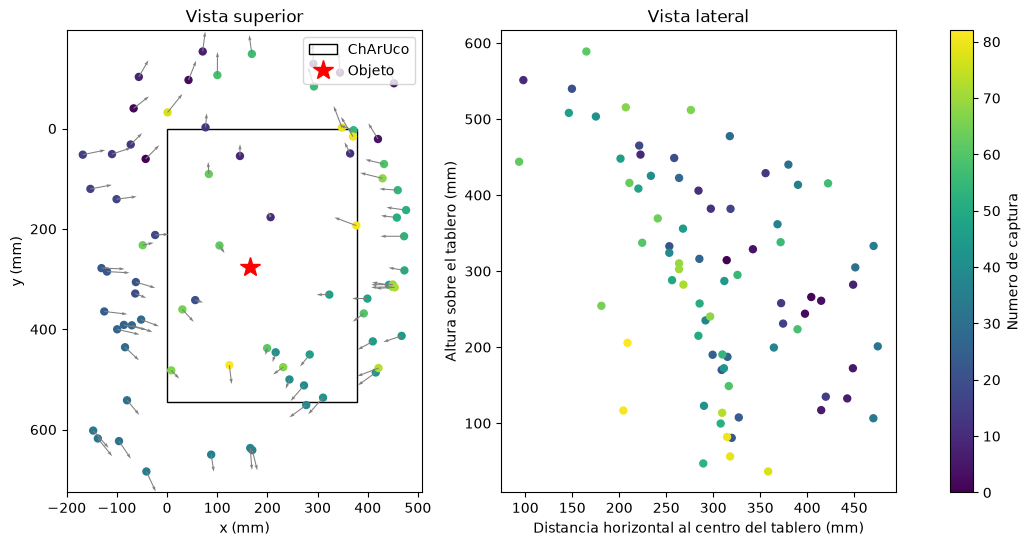

In [16]:
plot_camera_trajectory(fused_poses, BOARD_SIZE_MM, object_center=OBJECT_BOX.center,
                       path=FIG / "trayectoria_camaras.png")
board_scene = scene.crop(o3d.geometry.AxisAlignedBoundingBox([-60, -60, -200], [440, 610, 20]))
render_geometries(
    [board_scene, OBJECT_BOX] + camera_geometries(fused_poses, calibration["left_K"],
                                                  calibration["image_size"], axis_size=80),
    FIG / "poses_camaras.png", front=[-0.45, -0.55, -0.7], up=[0, 0, -1],
    lookat=[189, 273, -150], zoom=0.8, point_size=1.5
)

In [17]:
# Validacion opcional: referencia, evaluacion y nubes a alinear separadas.
icp_validation = validate_icp(clouds, fused_poses)
before, after = icp_validation[:, 1:3].mean(axis=0)
print(f"Correcciones aceptadas: {int(icp_validation[:, 3].sum())}/{len(icp_validation)}")
print(f"Distancia al grupo independiente: {before:.3f} -> {after:.3f} mm")
print(f"Mejora relativa: {100 * (1 - after / before):.1f} %")
print(f"Vistas que mejoran: {sum(icp_validation[:, 2] < icp_validation[:, 1])}/{len(icp_validation)}")

Correcciones aceptadas: 25/25
Distancia al grupo independiente: 1.144 -> 1.046 mm
Mejora relativa: 8.5 %
Vistas que mejoran: 23/25


In [18]:
# Refinamiento opcional del empalme con ICP.
clouds, fused_poses, icp_report = refine_clouds_icp(clouds, fused_poses)
print(f"ICP aplicado: {sum(r['applied'] for r in icp_report.values())}/{len(icp_report)} vistas")
icp_errors = np.array([[r["rmse_before"], r["rmse_after"]] for r in icp_report.values()])
print("RMSE medio antes/despues (mm):", np.round(icp_errors.mean(axis=0), 3))

ICP aplicado: 78/78 vistas
RMSE medio antes/despues (mm): [0.926 0.805]


In [19]:
fused = merge(clouds)
stages = optimize_cloud(fused, OUTLIER_NEIGHBORS, OUTLIER_STD, VOXEL_MM, RADIUS_POINTS, RADIUS_MM)
final_cloud = stages["radio"]

counts = {
    f"Escena completa ({len(accepted)} nubes)": sum(r["points"] for r in accepted.values()),
    "Caja del objeto": len(stages["caja"].points),
    "Outliers estadisticos": len(stages["estadistico"].points),
    f"Voxel {VOXEL_MM:g} mm": len(stages["voxel"].points),
    "Outliers por radio (final)": len(final_cloud.points),
}
for stage, count in counts.items():
    print(f"{stage:32s} {count:>12,}")

Escena completa (78 nubes)         83,667,820
Caja del objeto                     4,439,000
Outliers estadisticos               3,687,369
Voxel 1 mm                            389,839
Outliers por radio (final)            389,519


### Nube final interactiva

In [ ]:
o3d.visualization.draw_geometries(
    [final_cloud], window_name="Nube final",
    front=[0, 1, -0.4], up=[0, 0, -1], zoom=0.7
)

In [20]:
# Figuras de cada etapa: escena con la caja, recorte, filtrado y nube final desde tres vistas.
render_geometries([board_scene, OBJECT_BOX], FIG / "etapa_escena.png",
                  front=[-0.45, -0.55, -0.7], up=[0, 0, -1], lookat=[189, 273, -50], zoom=0.6)
center = final_cloud.get_center()
views = {"frente": ([0, 1, -0.4], [0, 0, -1]), "lado": ([1, 0, -0.4], [0, 0, -1]),
         "arriba": ([0, 0, -1], [0, -1, 0])}
render_geometries([fused.voxel_down_sample(VOXEL_MM)], FIG / "etapa_caja.png", *views["frente"], lookat=center)
render_geometries([stages["voxel"]], FIG / "etapa_estadistico_voxel.png", *views["frente"], lookat=center)
for name, (front, up) in views.items():
    render_geometries([final_cloud], FIG / f"final_{name}.png", front, up, lookat=center)

### Normales, Poisson (opcionales) y exportación

La orientación radial de normales es aproximada; la malla es experimental y no se usa para medir.

In [21]:
final_cloud.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=4 * VOXEL_MM, max_nn=30))
orient_normals_outward(final_cloud)

ply_path = Path("caracol.ply")
o3d.io.write_point_cloud(str(ply_path), final_cloud, write_ascii=False, compressed=False)
print(f"{ply_path}: {len(final_cloud.points):,} puntos, {ply_path.stat().st_size / 1e6:.1f} MB")

caracol.ply: 389,519 puntos, 19.9 MB


In [22]:
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(final_cloud, depth=9)
densities = np.asarray(densities)
mesh.remove_vertices_by_mask(densities < np.quantile(densities, 0.05))
mesh = mesh.crop(final_cloud.get_axis_aligned_bounding_box())
# Decimacion para que la malla pese del orden de la nube (~300k triangulos).
mesh = mesh.simplify_quadric_decimation(300_000)
mesh.compute_vertex_normals()
o3d.io.write_triangle_mesh("caracol_malla.ply", mesh)
print(f"Malla: {len(mesh.triangles):,} triangulos")
render_geometries([mesh], FIG / "malla_poisson.png", *views["frente"], lookat=center)

Malla: 299,999 triangulos


## 5. Medición métrica

Alto respecto del tablero, largo entre extremos horizontales y ancho perpendicular, en milímetros.

Alto : 131.2 mm
Largo: 238.7 mm
Ancho: 206.2 mm
OBB de Open3D (mm): [227.7 204.8 145.5]


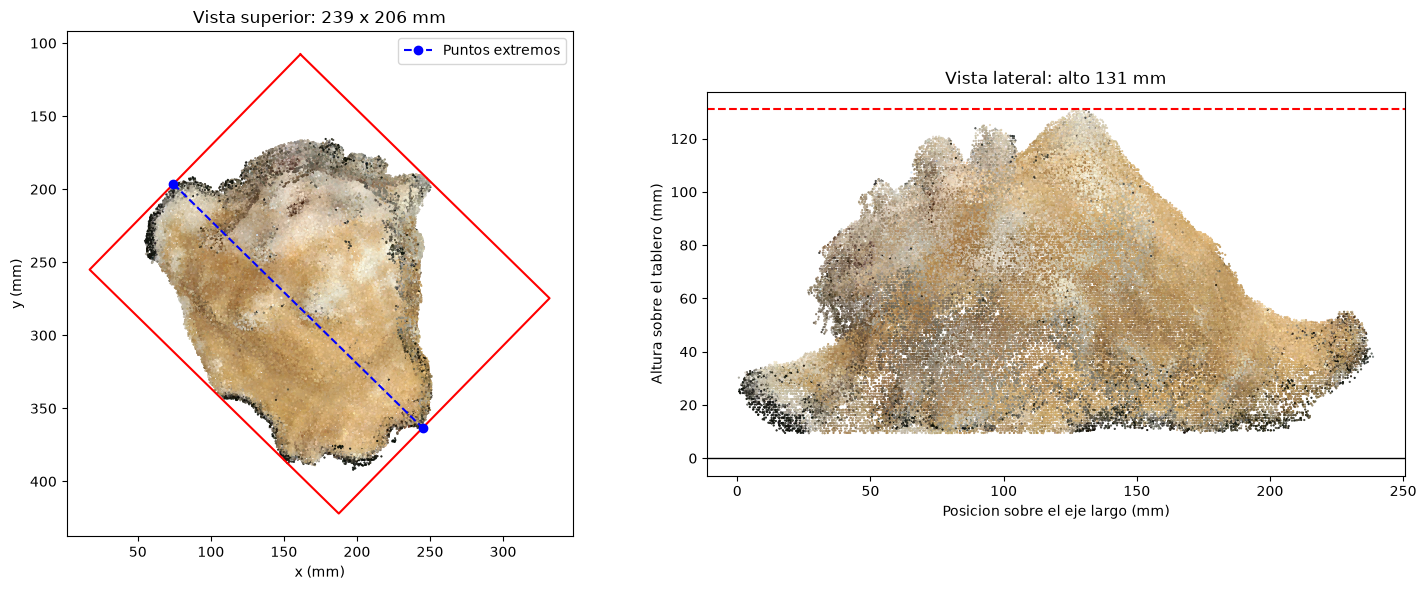

In [23]:
measurement = measure_object(final_cloud)
print(f"Alto : {measurement['alto_mm']:.1f} mm")
print(f"Largo: {measurement['largo_mm']:.1f} mm")
print(f"Ancho: {measurement['ancho_mm']:.1f} mm")
print("OBB de Open3D (mm):", np.round(measurement["obb_extent_mm"], 1))
plot_measurement(final_cloud, measurement, path=FIG / "medicion.png")

In [24]:
# Medidas reales del caracol tomadas con regla (completar): alto, largo, ancho en mm.
REAL_SIZE_MM = None  # p. ej. {"alto_mm": 120, "largo_mm": 215, "ancho_mm": 190}
if REAL_SIZE_MM:
    for key, real in REAL_SIZE_MM.items():
        estimated = measurement[key]
        print(f"{key}: estimado {estimated:.1f} mm, real {real:.1f} mm, "
              f"error relativo {100 * (estimated - real) / real:+.1f} %")